In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msn

from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [2]:
url = "https://github.com/Srabon-bot/Bangladesh-flood-data-set/raw/refs/heads/main/data/features/2026-08-07c/all_stations.parquet"
df = pd.read_parquet(url)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839340 entries, 0 to 839339
Data columns (total 49 columns):
 #   Column                              Non-Null Count   Dtype         
---  ------                              --------------   -----         
 0   date                                839340 non-null  datetime64[ns]
 1   station_id                          839340 non-null  object        
 2   station_name                        839340 non-null  object        
 3   rainfall_local_mm                   839340 non-null  float64       
 4   rainfall_upstream_mm                839340 non-null  float64       
 5   soil_moisture_local                 839340 non-null  float64       
 6   river_discharge_m3s                 324322 non-null  float64       
 7   flood_byStor                        4563 non-null    float64       
 8   rainfall_local_mm_missing           839340 non-null  bool          
 9   rainfall_upstream_mm_missing        839340 non-null  bool          
 10  soil_moi

In [4]:
df.describe()

,date,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,flood_byStor,rainfall_local_mm_lag1d,rainfall_local_mm_lag2d,rainfall_local_mm_lag3d,rainfall_local_mm_lag5d,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_48h,flood_within_72h,upstream_chain_discharge_lag1d,upstream_reference_discharge_lag2d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag3d
count,839340,839340.000000,839340.000000,839340.000000,324322.000000,4563.000000,839310.000000,839280.000000,839250.000000,839190.000000,...,839340.000000,839340.000000,839340.000000,100850.000000,101282.000000,101704.000000,86478.000000,43236.000000,10809.000000,10808.000000
mean,1988-04-19 12:00:00,6.666148,6.593339,0.306508,8320.198070,10.405439,6.665985,6.665701,6.664963,6.664009,...,0.306381,13.593333,2.166667,0.142251,0.167779,0.190553,22230.667965,764.002652,1398.926811,763.905841
min,1950-01-01 00:00:00,0.000000,0.000000,0.010000,0.000000,0.000069,0.000000,0.000000,0.000000,0.000000,...,0.023446,0.000000,0.000000,0.000000,0.000000,0.000000,60.800000,276.330000,438.540000,276.330000
25%,1969-02-24 00:00:00,0.000000,0.188889,0.195000,64.920000,0.849906,0.000000,0.000000,0.000000,0.000000,...,0.210420,6.600000,0.000000,0.000000,0.000000,0.000000,3898.420000,355.450000,624.170000,355.450000
50%,1988-04-19 12:00:00,0.800000,2.800000,0.333000,525.020000,2.973004,0.800000,0.800000,0.800000,0.800000,...,0.323310,11.700000,0.900000,0.000000,0.000000,0.000000,10255.520000,538.510000,1063.140000,538.510000
75%,2007-06-14 00:00:00,8.200000,9.877778,0.413000,5034.010000,9.091566,8.200000,8.200000,8.200000,8.200000,...,0.403440,18.400000,2.400000,0.000000,0.000000,0.000000,33418.520000,1123.610000,2088.300000,1123.610000
max,2026-08-07 00:00:00,389.800000,143.466667,0.515000,164436.200000,251.121338,389.800000,389.800000,389.800000,389.800000,...,0.504734,35.800000,13.300000,1.000000,1.000000,1.000000,153107.720000,3242.400000,5779.960000,3242.400000
std,NaN,13.261082,9.271268,0.118658,18941.082592,21.997433,13.261190,13.261135,13.260118,13.259799,...,0.108680,9.131414,3.363862,0.349309,0.373672,0.392739,25753.366997,486.333016,870.479764,486.268225


In [5]:
df.columns

Index(['date', 'station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'flood_byStor', 'rainfall_local_mm_missing',
       'rainfall_upstream_mm_missing', 'soil_moisture_local_missing',
       'river_discharge_m3s_missing', 'flood_byStor_missing',
       'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d',
       'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d',
       'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d',
       'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d',
       'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d',
       'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d',
       'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d',
       'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d',
       'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d',
       'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream

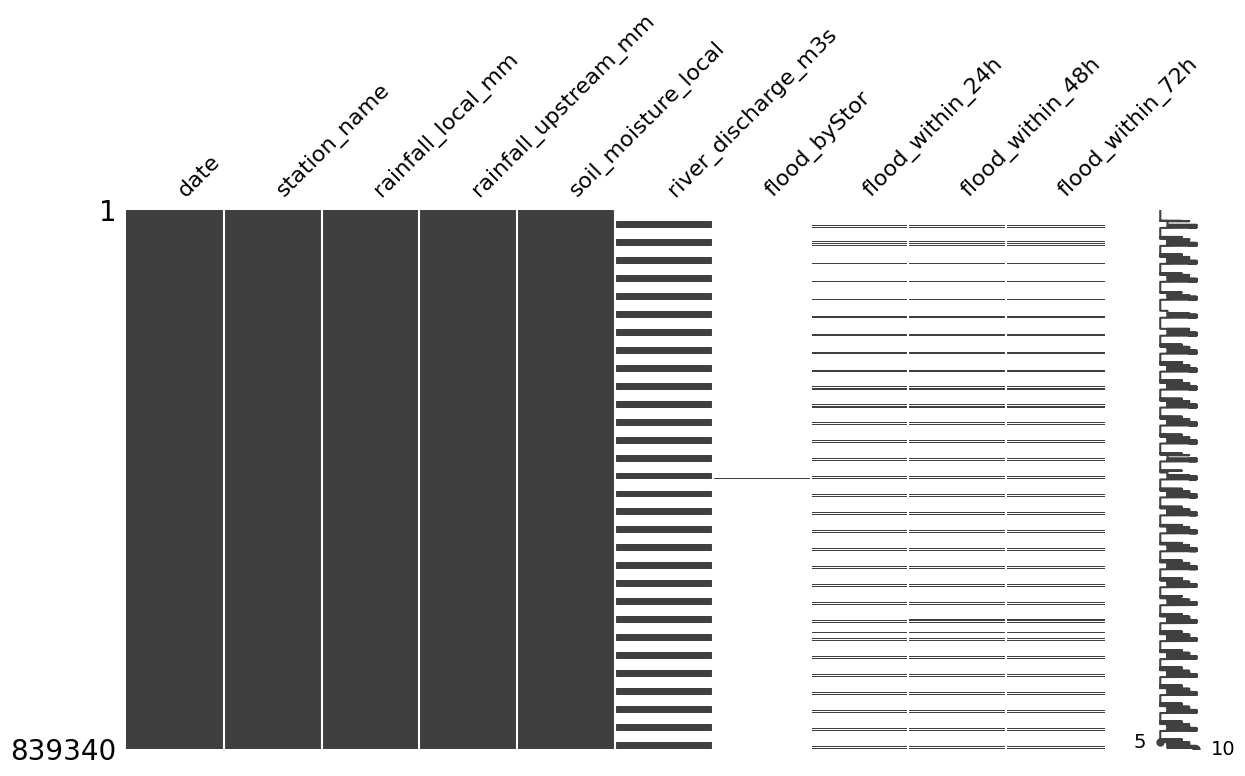

In [6]:
msn.matrix(df[[
        "date",
        "station_name",
        "rainfall_local_mm",
        "rainfall_upstream_mm",
        "soil_moisture_local",
        "river_discharge_m3s",
        "flood_byStor",
        "flood_within_24h",
        "flood_within_48h",
        "flood_within_72h"]],figsize=(14, 7));

In [7]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values (%):")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

print("\nFlood target distribution:")
print(df["flood_within_24h"].value_counts(dropna=False))

print("\nRows per station:")
print(df["station_id"].nunique())

print("\nSample:")
display(df.head())


Shape: (839340, 49)

Columns:
['date', 'station_id', 'station_name', 'rainfall_local_mm', 'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s', 'flood_byStor', 'rainfall_local_mm_missing', 'rainfall_upstream_mm_missing', 'soil_moisture_local_missing', 'river_discharge_m3s_missing', 'flood_byStor_missing', 'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d', 'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d', 'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d', 'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d', 'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d', 'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d', 'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d', 'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d', 'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d', 'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d', 'rainfall_upstream_mm_sum14d', 'rainfall_upstream_mm_trend_ratio', 'soil_moisture_delta_30d', 'soil

,date,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,flood_byStor,rainfall_local_mm_missing,rainfall_upstream_mm_missing,...,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,upstream_chain_discharge_lag1d,upstream_reference_discharge_lag2d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag3d
0,1950-01-01,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.242,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
1,1950-01-02,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.240,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
2,1950-01-03,CH01,Rangamati (Karnaphuli),0.0,0.044444,0.238,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
3,1950-01-04,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.240,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
4,1950-01-05,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.238,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN


In [8]:
# How the labels are made:
print("Label regimes:")
print(df["flood_within_24h_label_regime"].value_counts(dropna=False))

# How many labels are available per station?
station_labels = df.groupby("station_name").agg(total_rows=("flood_within_24h", "size"),known_labels=("flood_within_24h", "count"),flood_cases=("flood_within_24h", "sum"))

print("\nLabels per station:")
display(station_labels.sort_values("known_labels", ascending=False))


Label regimes:
flood_within_24h_label_regime
None                   738490
observed                91350
unobserved_positive      9500
Name: count, dtype: int64

Labels per station:


,total_rows,known_labels,flood_cases
station_name,,,
Chilmari,27978,3688,743.0
Hardinge Bridge (Kushtia),27978,3688,746.0
Amalshid,27978,3598,747.0
Sherpur (Sylhet),27978,3586,726.0
Sylhet,27978,3563,724.0
Sariakandi,27978,3550,628.0
Sirajganj,27978,3547,585.0
Mawa,27978,3526,665.0
Bahadurabad,27978,3525,606.0


In [9]:
# In which years do we have known labels?
df["year"] = df["date"].dt.year

year_labels = df.groupby("year").agg(known_labels=("flood_within_24h", "count"),flood_cases=("flood_within_24h", "sum"))

print("\nLabels by year:")
display(year_labels[year_labels["known_labels"] > 0])


Labels by year:


,known_labels,flood_cases
year,,
1985,166,166.0
1986,67,67.0
1987,640,640.0
1988,570,570.0
1989,74,74.0
1990,543,543.0
1991,348,348.0
1992,1,1.0
1994,39,39.0


In [10]:
# Keep only rows with observed labels
df_model = df[df["flood_within_24h_label_regime"] == "observed"].copy()

# Convert target to integer
df_model["flood_within_24h"] = (df_model["flood_within_24h"].astype(int))

# Check target distribution
print(df_model["flood_within_24h"].value_counts())

flood_within_24h
0    86504
1     4846
Name: count, dtype: int64


In [11]:
# Check labels by year
year_check = df_model.groupby("year").agg(total_rows=("flood_within_24h", "size"), flood_cases=("flood_within_24h", "sum"))

year_check["no_flood_cases"] = (year_check["total_rows"] - year_check["flood_cases"])

display(year_check)

,total_rows,flood_cases,no_flood_cases
year,,,
2012,30,0,30
2013,10950,377,10573
2014,10950,491,10459
2015,10950,1288,9662
2016,2700,4,2696
2020,30,0,30
2021,10950,515,10435
2022,10950,655,10295
2023,10950,542,10408


In [12]:
# Keep observed labels from 2021 to 2025
df_model = df[(df["flood_within_24h_label_regime"] == "observed") & (df["year"].between(2021, 2025))].copy()

# Sort chronologically
df_model = df_model.sort_values(["date", "station_id"]).reset_index(drop=True)

In [13]:
print("Shape:", df_model.shape)
print("Date range:", df_model["date"].min(), "to", df_model["date"].max())

print("\nTarget distribution:")
print(df_model["flood_within_24h"].value_counts())

print("\nMissing values in columns:")
print(df_model.isna().sum().sort_values(ascending=False))

Shape: (54780, 50)
Date range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00

Target distribution:
flood_within_24h
0.0    52094
1.0     2686
Name: count, dtype: int64

Missing values in columns:
upstream_chain_discharge_lag2d        52954
upstream_reference_discharge_lag3d    52954
flood_byStor                          52106
upstream_reference_discharge_lag2d    47476
upstream_chain_discharge_lag1d        40172
rainfall_local_mm_trend_ratio         12626
rainfall_upstream_mm_trend_ratio       1872
station_name                              0
station_id                                0
rainfall_upstream_mm_missing              0
soil_moisture_local_missing               0
river_discharge_m3s_missing               0
rainfall_upstream_mm                      0
rainfall_local_mm                         0
soil_moisture_local                       0
river_discharge_m3s                       0
rainfall_local_mm_missing                 0
date                                      0
rainfall_upstre

In [14]:
# Check duplicate rows
print("Duplicate rows:", df_model.duplicated().sum())

Duplicate rows: 0


In [15]:
# Check missing values as percentages
missing_pct = (df_model.isna().mean() * 100).sort_values(ascending=False)

display(missing_pct)

,0
upstream_chain_discharge_lag2d,96.666667
upstream_reference_discharge_lag3d,96.666667
flood_byStor,95.118656
upstream_reference_discharge_lag2d,86.666667
upstream_chain_discharge_lag1d,73.333333
rainfall_local_mm_trend_ratio,23.048558
rainfall_upstream_mm_trend_ratio,3.417306
station_name,0.000000
station_id,0.000000
rainfall_upstream_mm_missing,0.000000


In [16]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54780 entries, 0 to 54779
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   date                                54780 non-null  datetime64[ns]
 1   station_id                          54780 non-null  object        
 2   station_name                        54780 non-null  object        
 3   rainfall_local_mm                   54780 non-null  float64       
 4   rainfall_upstream_mm                54780 non-null  float64       
 5   soil_moisture_local                 54780 non-null  float64       
 6   river_discharge_m3s                 54780 non-null  float64       
 7   flood_byStor                        2674 non-null   float64       
 8   rainfall_local_mm_missing           54780 non-null  bool          
 9   rainfall_upstream_mm_missing        54780 non-null  bool          
 10  soil_moisture_local_mi

In [17]:
df_model.columns

Index(['date', 'station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'flood_byStor', 'rainfall_local_mm_missing',
       'rainfall_upstream_mm_missing', 'soil_moisture_local_missing',
       'river_discharge_m3s_missing', 'flood_byStor_missing',
       'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d',
       'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d',
       'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d',
       'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d',
       'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d',
       'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d',
       'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d',
       'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d',
       'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d',
       'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream

In [18]:
# Columns to exclude
cols_to_drop = ["upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag3d",
    "flood_byStor",
    "upstream_reference_discharge_lag2d",
    "upstream_chain_discharge_lag1d",
    "rainfall_local_mm_trend_ratio"]

df_clean = df_model.drop(columns=cols_to_drop)

print("Shape:", df_clean.shape)

# Check remaining missing values
missing = df_clean.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))

Shape: (54780, 44)


,0
rainfall_upstream_mm_trend_ratio,1872


In [19]:
df_clean["rainfall_upstream_mm_trend_ratio"].isna().sum()

np.int64(1872)

In [20]:
df_clean = df_clean.drop(columns=["rainfall_upstream_mm_trend_ratio"])

print("Shape:", df_clean.shape)

Shape: (54780, 43)


In [21]:
missing = df_clean.isna().sum()

print(missing)

date                             0
station_id                       0
station_name                     0
rainfall_local_mm                0
rainfall_upstream_mm             0
soil_moisture_local              0
river_discharge_m3s              0
rainfall_local_mm_missing        0
rainfall_upstream_mm_missing     0
soil_moisture_local_missing      0
river_discharge_m3s_missing      0
flood_byStor_missing             0
rainfall_local_mm_lag1d          0
rainfall_local_mm_lag2d          0
rainfall_local_mm_lag3d          0
rainfall_local_mm_lag5d          0
rainfall_upstream_mm_lag1d       0
rainfall_upstream_mm_lag2d       0
rainfall_upstream_mm_lag3d       0
rainfall_upstream_mm_lag5d       0
soil_moisture_local_lag1d        0
soil_moisture_local_lag2d        0
soil_moisture_local_lag3d        0
soil_moisture_local_lag5d        0
river_discharge_m3s_lag1d        0
river_discharge_m3s_lag2d        0
river_discharge_m3s_lag3d        0
river_discharge_m3s_lag5d        0
rainfall_local_mm_su

In [22]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54780 entries, 0 to 54779
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   date                           54780 non-null  datetime64[ns]
 1   station_id                     54780 non-null  object        
 2   station_name                   54780 non-null  object        
 3   rainfall_local_mm              54780 non-null  float64       
 4   rainfall_upstream_mm           54780 non-null  float64       
 5   soil_moisture_local            54780 non-null  float64       
 6   river_discharge_m3s            54780 non-null  float64       
 7   rainfall_local_mm_missing      54780 non-null  bool          
 8   rainfall_upstream_mm_missing   54780 non-null  bool          
 9   soil_moisture_local_missing    54780 non-null  bool          
 10  river_discharge_m3s_missing    54780 non-null  bool          
 11  flood_byStor_mi

In [23]:
df_clean.describe()

,date,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_lag1d,rainfall_local_mm_lag2d,rainfall_local_mm_lag3d,rainfall_local_mm_lag5d,rainfall_upstream_mm_lag1d,...,rainfall_upstream_mm_sum7d,rainfall_upstream_mm_sum14d,soil_moisture_delta_30d,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_48h,flood_within_72h,year
count,54780,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,...,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000
mean,2023-07-02 11:59:59.999999744,6.155283,6.048228,0.308205,8071.885354,6.155283,6.155257,6.155257,6.155248,6.048207,...,42.335196,84.667082,0.000052,0.308068,13.593333,2.166667,0.049032,0.072417,0.093428,2023.000548
min,2021-01-01 00:00:00,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-0.359000,0.031204,0.000000,0.000000,0.000000,0.000000,0.000000,2021.000000
25%,2022-04-02 00:00:00,0.000000,0.100000,0.220000,61.950000,0.000000,0.000000,0.000000,0.000000,0.100000,...,2.211111,6.688889,-0.055000,0.233468,6.600000,0.000000,0.000000,0.000000,0.000000,2022.000000
50%,2023-07-02 12:00:00,0.400000,2.277778,0.319000,476.530000,0.400000,0.400000,0.400000,0.400000,2.277778,...,24.600000,54.900000,-0.002000,0.315499,11.700000,0.900000,0.000000,0.000000,0.000000,2023.000000
75%,2024-10-01 00:00:00,7.000000,9.022222,0.401000,4796.330000,7.000000,7.000000,7.000000,7.000000,9.022222,...,69.055556,146.911111,0.049000,0.386711,18.400000,2.400000,0.000000,0.000000,0.000000,2024.000000
max,2025-12-31 00:00:00,389.800000,95.166667,0.514000,131824.640000,389.800000,389.800000,389.800000,389.800000,95.166667,...,318.000000,460.022222,0.378000,0.503450,35.800000,13.300000,1.000000,1.000000,1.000000,2025.000000
std,NaN,13.026416,8.744743,0.108595,18124.608509,13.026416,13.026428,13.026428,13.026432,8.744757,...,48.155285,87.133671,0.092507,0.095833,9.131492,3.363891,0.215938,0.259179,0.291034,1.414033


In [24]:
df_clean = df_clean.set_index("date")

In [25]:
df_clean.head()

,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_missing,rainfall_upstream_mm_missing,soil_moisture_local_missing,river_discharge_m3s_missing,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,year
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,CH01,Rangamati (Karnaphuli),0.0,0.0,0.297,206.49,False,False,False,False,...,0.317899,35.8,7.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH02,Bandarban (Sangu),0.0,0.0,0.212,49.23,False,False,False,False,...,0.224850,22.1,1.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH03,Chittagong (Halda),0.0,0.0,0.172,256.63,False,False,False,False,...,0.191675,5.0,0.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO01,Barisal,0.0,0.0,0.223,10.02,False,False,False,False,...,0.249996,7.3,0.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO02,Khulna (Rupsha),0.0,0.0,0.276,124.89,False,False,False,False,...,0.287952,4.8,0.0,0.0,observed,0.0,observed,0.0,observed,2021


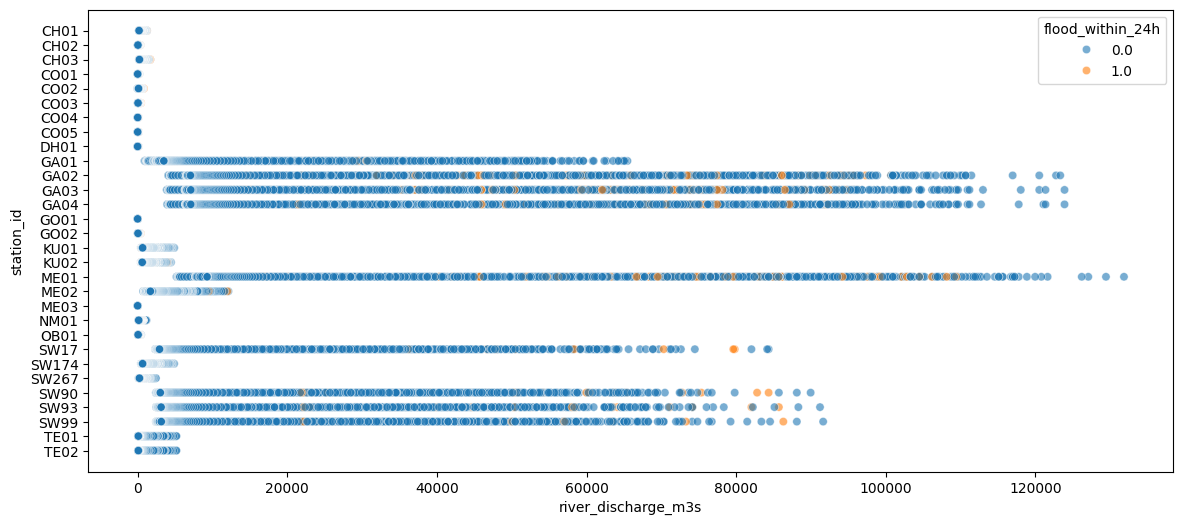

In [26]:
figure, axis = plt.subplots(figsize=(14, 6))

sns.scatterplot(
     df_clean
    ,x="river_discharge_m3s"
    ,y="station_id"
    ,hue="flood_within_24h"
    ,alpha=0.6);

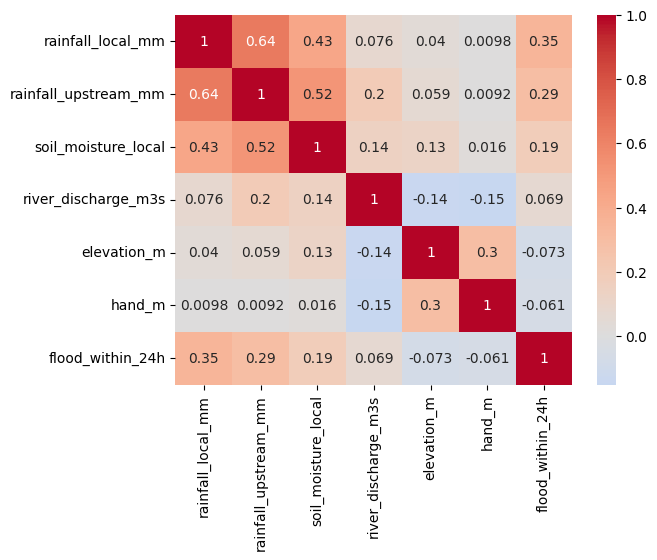

In [27]:
cols = [
    "rainfall_local_mm",
    "rainfall_upstream_mm",
    "soil_moisture_local",
    "river_discharge_m3s",
    "elevation_m",
    "hand_m",
    "flood_within_24h"]

sns.heatmap(df_clean[cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.show()

In [28]:
df_clean.columns

Index(['station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'rainfall_local_mm_missing', 'rainfall_upstream_mm_missing',
       'soil_moisture_local_missing', 'river_discharge_m3s_missing',
       'flood_byStor_missing', 'rainfall_local_mm_lag1d',
       'rainfall_local_mm_lag2d', 'rainfall_local_mm_lag3d',
       'rainfall_local_mm_lag5d', 'rainfall_upstream_mm_lag1d',
       'rainfall_upstream_mm_lag2d', 'rainfall_upstream_mm_lag3d',
       'rainfall_upstream_mm_lag5d', 'soil_moisture_local_lag1d',
       'soil_moisture_local_lag2d', 'soil_moisture_local_lag3d',
       'soil_moisture_local_lag5d', 'river_discharge_m3s_lag1d',
       'river_discharge_m3s_lag2d', 'river_discharge_m3s_lag3d',
       'river_discharge_m3s_lag5d', 'rainfall_local_mm_sum7d',
       'rainfall_local_mm_sum14d', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream_mm_sum14d', 'soil_moisture_delta_30d',
       'soil_moisture_sw

In [29]:
df_clean["station_id"].unique()

array(['CH01', 'CH02', 'CH03', 'CO01', 'CO02', 'CO03', 'CO04', 'CO05',
       'DH01', 'GA01', 'GA02', 'GA03', 'GA04', 'GO01', 'GO02', 'KU01',
       'KU02', 'ME01', 'ME02', 'ME03', 'NM01', 'OB01', 'SW17', 'SW174',
       'SW267', 'SW90', 'SW93', 'SW99', 'TE01', 'TE02'], dtype=object)

In [30]:
# From 1826 rows only 63 shows that floods occured for CH01 monitoring station

df_clean[(df_clean["station_id"] == "CH01") &(df_clean["flood_within_24h"] == 1)]


,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_missing,rainfall_upstream_mm_missing,soil_moisture_local_missing,river_discharge_m3s_missing,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,year
date,,,,,,,,,,,,,,,,,,,,,
2022-08-22,CH01,Rangamati (Karnaphuli),27.7,17.344444,0.416,192.64,False,False,False,False,...,0.396354,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2022
2023-07-24,CH01,Rangamati (Karnaphuli),6.5,5.577778,0.375,173.58,False,False,False,False,...,0.365090,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-07-25,CH01,Rangamati (Karnaphuli),4.1,11.266667,0.391,173.58,False,False,False,False,...,0.366825,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-07-31,CH01,Rangamati (Karnaphuli),6.9,20.033333,0.385,175.20,False,False,False,False,...,0.371873,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-08-07,CH01,Rangamati (Karnaphuli),74.5,61.111111,0.430,194.88,False,False,False,False,...,0.390588,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-09-15,CH01,Rangamati (Karnaphuli),5.9,7.955556,0.415,1190.24,False,False,False,False,...,0.410938,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024
2024-09-20,CH01,Rangamati (Karnaphuli),1.5,3.933333,0.382,1215.19,False,False,False,False,...,0.404430,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024
2024-09-23,CH01,Rangamati (Karnaphuli),3.2,12.577778,0.401,1149.80,False,False,False,False,...,0.400783,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024


Text(0, 0.5, 'Local Soil Moisture')

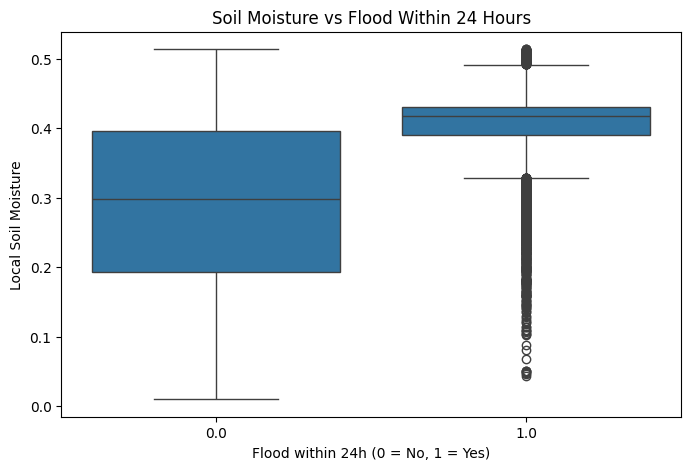

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="flood_within_24h", y="soil_moisture_local")

plt.title("Soil Moisture vs Flood Within 24 Hours")
plt.xlabel("Flood within 24h (0 = No, 1 = Yes)")
plt.ylabel("Local Soil Moisture")